# Exercício 6.7 — Percepção de uma marca de relógios inteligentes

Análise fatorial dos seis itens do questionário (n = 300), seguindo o Capítulo 6 de *Métodos Estatísticos Multivariados*.

| Item | Descrição |
|---|---|
| $X_1$ | as medições de batimentos cardíacos são precisas |
| $X_2$ | o GPS integrado registra minhas rotas sem falhas |
| $X_3$ | o design é moderno e elegante |
| $X_4$ | as opções de pulseira são esteticamente atraentes |
| $X_5$ | o relógio resiste a quedas e ao uso intenso em treinos |
| $X_6$ | a bateria dura o tempo prometido pelo fabricante |

O notebook usa só `numpy`, `scipy`, `pandas` e `matplotlib`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 3)

itens = [f"X{j}" for j in range(1, 7)]
n = 300

R = np.array([
    [1.00, 0.72, 0.15, 0.10, 0.65, 0.60],
    [0.72, 1.00, 0.12, 0.08, 0.70, 0.62],
    [0.15, 0.12, 1.00, 0.78, 0.10, 0.14],
    [0.10, 0.08, 0.78, 1.00, 0.05, 0.11],
    [0.65, 0.70, 0.10, 0.05, 1.00, 0.58],
    [0.60, 0.62, 0.14, 0.11, 0.58, 1.00],
])
p = R.shape[0]
pd.DataFrame(R, index=itens, columns=itens)

,X1,X2,X3,X4,X5,X6
X1,1.00,0.72,0.15,0.10,0.65,0.60
X2,0.72,1.00,0.12,0.08,0.70,0.62
X3,0.15,0.12,1.00,0.78,0.10,0.14
X4,0.10,0.08,0.78,1.00,0.05,0.11
X5,0.65,0.70,0.10,0.05,1.00,0.58
X6,0.60,0.62,0.14,0.11,0.58,1.00


## a) Estrutura de blocos

Reordenando as variáveis para juntar os itens parecidos, a estrutura fica visível no mapa de calor.

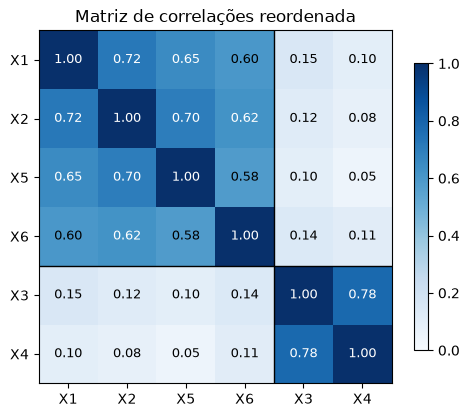

Dentro do bloco {X1,X2,X5,X6}: 0.58 a 0.72
Dentro do bloco {X3,X4}:       0.78
Entre os blocos:               0.05 a 0.15


In [2]:
ordem = [0, 1, 4, 5, 2, 3]  # X1, X2, X5, X6 | X3, X4
rot = [itens[i] for i in ordem]

fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(R[np.ix_(ordem, ordem)], cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(p), rot); ax.set_yticks(range(p), rot)
for i in range(p):
    for j in range(p):
        v = R[ordem[i], ordem[j]]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="white" if v > 0.6 else "black", fontsize=9)
ax.axhline(3.5, color="k", lw=1); ax.axvline(3.5, color="k", lw=1)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Matriz de correlações reordenada")
plt.tight_layout(); plt.show()

bloco1, bloco2 = [0, 1, 4, 5], [2, 3]
fora = lambda idx: R[np.ix_(idx, idx)][~np.eye(len(idx), dtype=bool)]
print("Dentro do bloco {X1,X2,X5,X6}:", fora(bloco1).min(), "a", fora(bloco1).max())
print("Dentro do bloco {X3,X4}:      ", R[2, 3])
entre = R[np.ix_(bloco1, bloco2)]
print("Entre os blocos:              ", entre.min(), "a", entre.max())

Há dois blocos: **{X1, X2, X5, X6}**, com correlações altas entre si, e **{X3, X4}**, também muito correlacionados. Entre os blocos as correlações são baixas.

Esperamos então **2 fatores**:
- **F1 — desempenho/funcionalidade**: precisão dos sensores, GPS, resistência e bateria;
- **F2 — estética/aparência**: design e pulseiras.

Os autovalores confirmam: só os dois primeiros passam de 1 (critério de Kaiser), e há um cotovelo nítido depois do segundo.

Autovalores: [3.012 1.71  0.443 0.349 0.268 0.218]


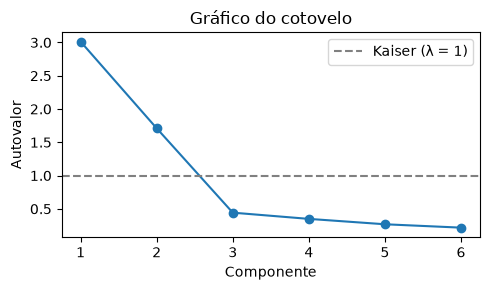

In [3]:
autovalores, autovetores = np.linalg.eigh(R)
idx = np.argsort(autovalores)[::-1]
autovalores, autovetores = autovalores[idx], autovetores[:, idx]

print("Autovalores:", autovalores)

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(range(1, p + 1), autovalores, "o-")
ax.axhline(1, ls="--", color="gray", label="Kaiser (λ = 1)")
ax.set_xlabel("Componente"); ax.set_ylabel("Autovalor")
ax.set_title("Gráfico do cotovelo"); ax.legend()
plt.tight_layout(); plt.show()

## b) Solução por componentes principais com $m = 2$

As cargas são $\hat{\ell}_{\cdot k} = \sqrt{\hat\lambda_k}\,\hat{\boldsymbol e}_k$ (Definição 6.2), e a proporção da variância total explicada pelo fator $k$ é $\hat\lambda_k / p$ (Proposição 6.3).

In [4]:
m = 2
L_cp = autovetores[:, :m] * np.sqrt(autovalores[:m])
L_cp *= np.sign(L_cp.sum(axis=0))  # orientação: cargas positivas na maioria

h2 = (L_cp**2).sum(axis=1)
psi = 1 - h2

tab_cp = pd.DataFrame({"F1": L_cp[:, 0], "F2": L_cp[:, 1], "h²": h2, "ψ": psi}, index=itens)
display(tab_cp)

prop = autovalores[:m] / p
print(f"Proporção explicada por F1: {prop[0]:.1%}")
print(f"Proporção explicada por F2: {prop[1]:.1%}")
print(f"Total (λ1 + λ2)/p = ({autovalores[0]:.2f} + {autovalores[1]:.2f})/{p} = {prop.sum():.1%}")

,F1,F2,h²,ψ
X1,0.858,-0.135,0.755,0.245
X2,0.874,-0.174,0.795,0.205
X3,0.316,0.888,0.889,0.111
X4,0.265,0.906,0.892,0.108
X5,0.835,-0.196,0.736,0.264
X6,0.802,-0.111,0.656,0.344


Proporção explicada por F1: 50.2%
Proporção explicada por F2: 28.5%
Total (λ1 + λ2)/p = (3.01 + 1.71)/6 = 78.7%


In [17]:
autovalores

array([3.012, 1.71 , 0.443, 0.349, 0.268, 0.218])

Os dois fatores explicam cerca de **78,7%** da variância total.

Essa proporção vem da ACP e inclui a variância específica de cada item, então tende a superestimar o que os fatores comuns explicam de fato.

Resíduos fora da diagonal e o limite da Proposição 6.2:

In [5]:
residuos = R - (L_cp @ L_cp.T + np.diag(psi))
display(pd.DataFrame(residuos, index=itens, columns=itens).round(3))

fora_diag = residuos[~np.eye(p, dtype=bool)]
print("Soma dos quadrados dos resíduos fora da diagonal:", (fora_diag**2).sum().round(3))
print("Limite: soma dos λ² descartados                  :", (autovalores[m:]**2).sum().round(3))

,X1,X2,X3,X4,X5,X6
X1,0.000,-0.054,-0.002,-0.005,-0.093,-0.104
X2,-0.054,0.000,-0.001,0.007,-0.064,-0.101
X3,-0.002,-0.001,0.000,-0.109,0.011,-0.015
X4,-0.005,0.007,-0.109,0.000,0.007,-0.002
X5,-0.093,-0.064,0.011,0.007,0.000,-0.112
X6,-0.104,-0.101,-0.015,-0.002,-0.112,0.000


Soma dos quadrados dos resíduos fora da diagonal: 0.123
Limite: soma dos λ² descartados                  : 0.437


## c) Graus de liberdade e teste de ajuste

Pela Equação 6.5:

$$\text{gl} = \tfrac12\left[(p-m)^2 - (p+m)\right] = \tfrac12\left[(6-2)^2 - (6+2)\right] = 4$$

Como $\text{gl} > 0$, o modelo impõe restrições que os dados podem contrariar, e **o ajuste pode ser testado**. O teste da razão de verossimilhanças exige estimativas de **máxima verossimilhança**, então ajustamos o modelo por MV (como no Exemplo 6.4) e aplicamos a estatística de Bartlett (Equação 6.4).

Pela invariância de escala da MV, usar $\boldsymbol R$ no lugar de $\boldsymbol S_n$ não altera a razão de determinantes.

In [6]:
gl = ((p - m)**2 - (p + m)) / 2
print("Graus de liberdade:", int(gl))

def menos_logvero(theta):
    L = theta[:p * m].reshape(p, m)
    psi_ = np.exp(theta[p * m:])
    Sigma = L @ L.T + np.diag(psi_)
    return np.linalg.slogdet(Sigma)[1] + np.trace(np.linalg.solve(Sigma, R))

inicio = np.concatenate([L_cp.ravel(), np.log(np.clip(psi, 0.05, None))])
ajuste = minimize(menos_logvero, inicio, method="L-BFGS-B", options={"maxiter": 5000})
L_mv = ajuste.x[:p * m].reshape(p, m)
psi_mv = np.exp(ajuste.x[p * m:])
print("Convergiu:", ajuste.success)

Sigma_mv = L_mv @ L_mv.T + np.diag(psi_mv)
log_razao = np.linalg.slogdet(Sigma_mv)[1] - np.linalg.slogdet(R)[1]
qui2 = (n - 1 - (2 * p + 4 * m + 5) / 6) * log_razao
p_valor = stats.chi2.sf(qui2, gl)
print(f"Estatística χ² = {qui2:.2f}, gl = {int(gl)}, p-valor = {p_valor:.4f}")

print("\nComunalidades MV:", (1 - psi_mv).round(3))
print("Variâncias específicas MV:", psi_mv.round(3))

Graus de liberdade: 4
Convergiu: True
Estatística χ² = 0.83, gl = 4, p-valor = 0.9344

Comunalidades MV: [0.679 0.76  0.725 0.844 0.64  0.52 ]
Variâncias específicas MV: [0.321 0.24  0.275 0.156 0.36  0.48 ]


Com $n = 300$ o teste é informativo: a amostra não é tão grande a ponto de rejeitar qualquer discrepância mínima, como acontecia no exemplo do Big Five. Aqui a estatística vale cerca de **0,82** com 4 graus de liberdade (p-valor ≈ **0,94**), então **não rejeitamos** a hipótese de que 2 fatores bastam: o modelo reproduz bem a matriz de correlações.

(Note que as cargas de MV podem sair numa orientação diferente das de CP, pois a MV fixa a rotação por outra convenção. Comunalidades e ajuste não dependem disso.)

## d) Rotação varimax

Implementação da varimax pelo algoritmo baseado em SVD, sem normalização de Kaiser, usando o critério da Equação 6.6.

In [7]:
def varimax(L, tol=1e-10, max_iter=1000):
    p_, k = L.shape
    T = np.eye(k)
    V_ant = 0
    for _ in range(max_iter):
        A = L @ T
        G = L.T @ (A**3 - A @ np.diag((A**2).sum(axis=0)) / p_)
        u, s, vt = np.linalg.svd(G)
        T = u @ vt
        V = s.sum()
        if V - V_ant < tol:
            break
        V_ant = V
    return L @ T, T

def criterio_varimax(L):
    return (L**2).var(axis=0, ddof=0).sum()

L_rot, T = varimax(L_cp)
angulo = np.degrees(np.arctan2(T[1, 0], T[0, 0]))

tab = pd.DataFrame(np.column_stack([L_cp, L_rot, h2]), index=itens,
                   columns=["F1 CP", "F2 CP", "F1 varimax", "F2 varimax", "h²"])
display(tab)
print("Matriz de rotação T:\n", T)
print(f"Ângulo de rotação: {angulo:.1f}°")
print(f"Critério V: {criterio_varimax(L_cp):.4f} → {criterio_varimax(L_rot):.4f}")
print("Comunalidades iguais após a rotação:", np.allclose((L_rot**2).sum(1), h2))

,F1 CP,F2 CP,F1 varimax,F2 varimax,h²
X1,0.858,-0.135,0.865,0.086,0.755
X2,0.874,-0.174,0.890,0.051,0.795
X3,0.316,0.888,0.083,0.939,0.889
X4,0.265,0.906,0.028,0.944,0.892
X5,0.835,-0.196,0.858,0.020,0.736
X6,0.802,-0.111,0.804,0.095,0.656


Matriz de rotação T:
 [[ 0.968  0.251]
 [-0.251  0.968]]
Ângulo de rotação: -14.6°
Critério V: 0.2240 → 0.2920
Comunalidades iguais após a rotação: True


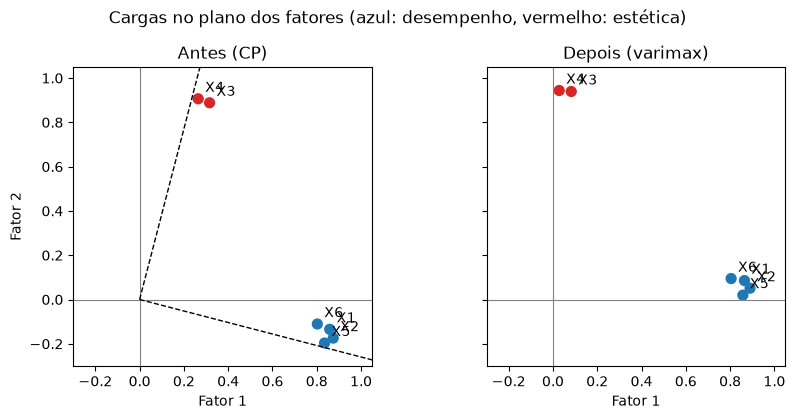

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharex=True, sharey=True)
for ax, L, titulo in zip(axes, [L_cp, L_rot], ["Antes (CP)", "Depois (varimax)"]):
    ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
    cores = ["C0" if j in bloco1 else "C3" for j in range(p)]
    ax.scatter(L[:, 0], L[:, 1], c=cores, s=50)
    for j in range(p):
        ax.annotate(itens[j], (L[j, 0], L[j, 1]), textcoords="offset points", xytext=(5, 5))
    ax.set_xlim(-0.3, 1.05); ax.set_ylim(-0.3, 1.05)
    ax.set_xlabel("Fator 1"); ax.set_title(titulo); ax.set_aspect("equal")
axes[0].set_ylabel("Fator 2")
# eixos rotacionados no painel da esquerda
for k in range(2):
    d = T[:, k]
    axes[0].plot([0, 1.1 * d[0]], [0, 1.1 * d[1]], "k--", lw=1)
plt.suptitle("Cargas no plano dos fatores (azul: desempenho, vermelho: estética)")
plt.tight_layout(); plt.show()

**Conclusão do item d.** A varimax gira os eixos em cerca de **15°**, uma mudança **pequena**. Os dois blocos já eram quase não correlacionados, então a solução por CP já estava perto de uma estrutura simples.

O efeito da rotação é limpar as cargas cruzadas: X3 e X4 tinham cerca de 0,3 em F1 e caem para menos de 0,1, e as pequenas cargas negativas dos itens de desempenho em F2 desaparecem. Depois do giro, F1 é claramente **desempenho/funcionalidade** e F2 é **estética**.

Comunalidades, variâncias específicas e resíduos não mudam com a rotação, apenas a forma como as cargas se distribuem entre os fatores.